## Environment Setup & Fast Data Staging



In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import sys
import shutil
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Detect environment
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Running in Google Colab environment")
    from google.colab import drive, files
    drive.mount('/content/drive')

    # Path to dataset in Google Drive
    DRIVE_DATASET_PATH = '/content/drive/MyDrive/DataNew'

    # Fast local working directory on Colab SSD
    LOCAL_DATASET_PATH = '/content/DataNew'

    # Optimization: Copy dataset to fast local disk (/content) to avoid Drive FUSE I/O lag
    if not os.path.exists(LOCAL_DATASET_PATH):
        if os.path.isdir(DRIVE_DATASET_PATH):
            print(f"Copying dataset from Drive to local SSD for ultra-fast training")
            shutil.copytree(DRIVE_DATASET_PATH, LOCAL_DATASET_PATH)
        else:
            print(f"Drive path {DRIVE_DATASET_PATH} not found. Please check your Drive path.")
            LOCAL_DATASET_PATH = DRIVE_DATASET_PATH

    DATASET_PATH = LOCAL_DATASET_PATH if os.path.exists(LOCAL_DATASET_PATH) else DRIVE_DATASET_PATH
    MODELS_DIR = '/content/drive/MyDrive/Models'
else:
    print("Running in Local environment.")
    DATASET_PATH = os.path.abspath('DataNew')
    MODELS_DIR = os.path.abspath('Models')

os.makedirs(MODELS_DIR, exist_ok=True)
print(f"Active Dataset Path: {DATASET_PATH}")
print(f"Models Output Directory: {MODELS_DIR}")

Running in Google Colab environment
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copying dataset from Drive to local SSD for ultra-fast training
Active Dataset Path: /content/DataNew
Models Output Directory: /content/drive/MyDrive/Models


## Hardware Acceleration & Mixed Precision



In [3]:
import tensorflow as tf

print(f"TensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU Available: {gpus}")
    try:
        from tensorflow.keras import mixed_precision
        mixed_precision.set_global_policy('mixed_float16')
        print("Mixed precision policy set to: mixed_float16")
    except Exception as e:
        print(f"Mixed precision note: {e}")
else:
    print("No GPU detected. Running on CPU (training may be slower).")


TensorFlow Version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision policy set to: mixed_float16


## Global Hyperparameters & Configurations


In [4]:
# Set reproducible random seeds
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# Hyperparameters
IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)
BATCH_SIZE = 32
INITIAL_EPOCHS = 15
FINE_TUNE_EPOCHS = 15
VALIDATION_SPLIT = 0.2
AUTOTUNE = tf.data.AUTOTUNE

print(f"Image Resolution: {IMG_SIZE}")
print(f"Batch Size: {BATCH_SIZE}")
print(f"Validation Split: {VALIDATION_SPLIT * 100}%")


Image Resolution: (224, 224)
Batch Size: 32
Validation Split: 20.0%


## Dataset Exploration & Class Distribution Analysis


Found 17 landmark classes:


,Class,Count
14,Sigiriya,548
12,Ramboda_Falls,522
2,Dambulla_cave_temple,480
10,Peradeniya_garden,460
15,Temple_Of_The_Tooth,384
13,Ruwanweli_Maha_Seya,345
11,Polannaruwa_Vatadage,335
8,Nallur_Kovil,327
1,Commonwealth_war_cemetery,315
0,Ambuluwawa,263


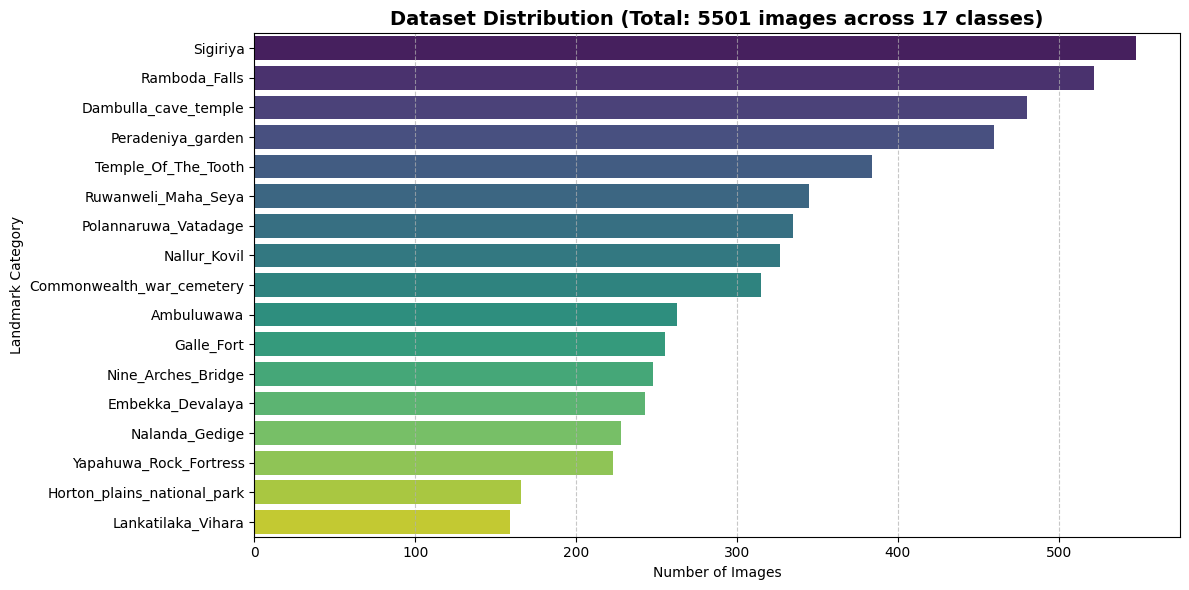

In [5]:
import glob
from sklearn.utils.class_weight import compute_class_weight

# Scan dataset directory
classes_found = [d for d in sorted(os.listdir(DATASET_PATH)) if os.path.isdir(os.path.join(DATASET_PATH, d))]
print(f"Found {len(classes_found)} landmark classes:")

class_counts = {}
total_images = 0
valid_exts = ('.jpg', '.jpeg', '.png', '.webp', '.bmp')

for cls_name in classes_found:
    cls_path = os.path.join(DATASET_PATH, cls_name)
    imgs = [f for f in os.listdir(cls_path) if f.lower().endswith(valid_exts)]
    class_counts[cls_name] = len(imgs)
    total_images += len(imgs)

df_counts = pd.DataFrame(list(class_counts.items()), columns=['Class', 'Count']).sort_values(by='Count', ascending=False)

display(df_counts)

plt.figure(figsize=(12, 6))
sns.barplot(x='Count', y='Class', data=df_counts, palette='viridis', hue='Class', legend=False)
plt.title(f"Dataset Distribution (Total: {total_images} images across {len(classes_found)} classes)", fontsize=14, fontweight='bold')
plt.xlabel("Number of Images")
plt.ylabel("Landmark Category")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## High-Performance `tf.data` Loading Pipeline


In [6]:
# Load Training Dataset
raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=VALIDATION_SPLIT,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

# Load Validation Dataset
raw_val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=VALIDATION_SPLIT,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

class_names = raw_train_ds.class_names
num_classes = len(class_names)
print(f"\nSuccessfully loaded {num_classes} classes:")
for idx, name in enumerate(class_names):
    print(f"  [{idx:02d}] {name}")

# Export class names and indices for mobile/web deployment
labels_txt_path = os.path.join(MODELS_DIR, 'labels.txt')
with open(labels_txt_path, 'w', encoding='utf-8') as f:
    for name in class_names:
        f.write(f"{name}\n")

class_indices_path = os.path.join(MODELS_DIR, 'class_indices.json')
with open(class_indices_path, 'w', encoding='utf-8') as f:
    json.dump({name: idx for idx, name in enumerate(class_names)}, f, indent=4)

print(f"\nSaved 'labels.txt' and 'class_indices.json' to {MODELS_DIR}")


Found 5500 files belonging to 17 classes.
Using 4400 files for training.
Found 5500 files belonging to 17 classes.
Using 1100 files for validation.

Successfully loaded 17 classes:
  [00] Ambuluwawa
  [01] Commonwealth_war_cemetery
  [02] Dambulla_cave_temple
  [03] Embekka_Devalaya
  [04] Galle_Fort
  [05] Horton_plains_national_park
  [06] Lankatilaka_Vihara
  [07] Nalanda_Gedige
  [08] Nallur_Kovil
  [09] Nine_Arches_Bridge
  [10] Peradeniya_garden
  [11] Polannaruwa_Vatadage
  [12] Ramboda_Falls
  [13] Ruwanweli_Maha_Seya
  [14] Sigiriya
  [15] Temple_Of_The_Tooth
  [16] Yapahuwa_Rock_Fortress

Saved 'labels.txt' and 'class_indices.json' to /content/drive/MyDrive/Models


### Compute Balanced Class Weights
To ensure minority classes receive proportional attention during loss optimization


In [7]:
# Compute Class Weights for balanced loss penalization
all_labels = []
for _, labels in raw_train_ds:
    all_labels.extend(np.argmax(labels.numpy(), axis=1))

class_weights_arr = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(all_labels),
    y=np.array(all_labels)
)
class_weight_dict = dict(enumerate(class_weights_arr))
print("Computed Class Weights (first 5 shown):")
for i in range(min(5, len(class_weight_dict))):
    print(f"  Class {i} ({class_names[i]}): {class_weight_dict[i]:.4f}")


Computed Class Weights (first 5 shown):
  Class 0 (Ambuluwawa): 1.2038
  Class 1 (Commonwealth_war_cemetery): 0.9730
  Class 2 (Dambulla_cave_temple): 0.6705
  Class 3 (Embekka_Devalaya): 1.3273
  Class 4 (Galle_Fort): 1.1983


## GPU-Accelerated Data Augmentation & Prefetching


In [8]:
from tensorflow.keras import layers

# GPU Data Augmentation Sequential Block
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

# Rescaling layer (converts [0, 255] to [0.0, 1.0])
rescale_layer = layers.Rescaling(1./255, name="rescaling")

# Configure dataset with cache() and prefetch(AUTOTUNE)
def prepare_train_ds(ds):
    return ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE) \
             .cache() \
             .shuffle(buffer_size=1000) \
             .prefetch(buffer_size=AUTOTUNE)

def prepare_val_ds(ds):
    return ds.cache().prefetch(buffer_size=AUTOTUNE)

train_ds = prepare_train_ds(raw_train_ds)
val_ds = prepare_val_ds(raw_val_ds)

print("Datasets successfully cached and prefetch-optimized for GPU training.")


Datasets successfully cached and prefetch-optimized for GPU training.


### Visualize Augmented Training Samples


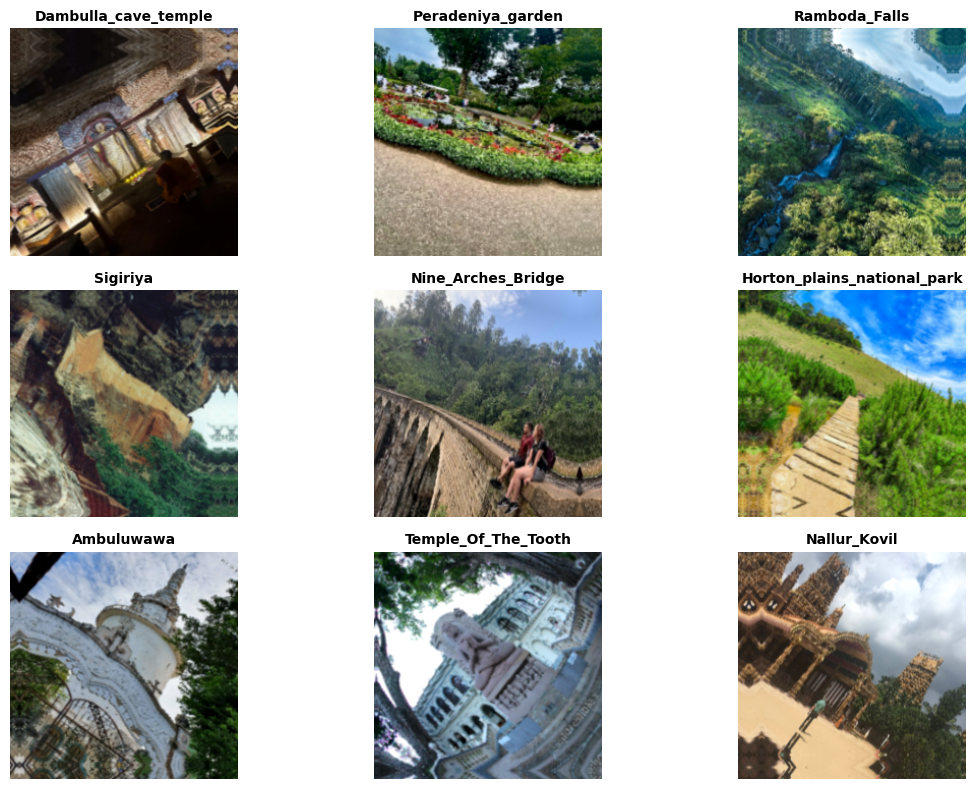

In [9]:
plt.figure(figsize=(12, 8))
for images, labels in raw_train_ds.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)
        aug_img = data_augmentation(tf.expand_dims(images[i], 0), training=True)[0]
        plt.imshow(aug_img.numpy().astype("uint8"))
        cls_idx = np.argmax(labels[i].numpy())
        plt.title(f"{class_names[cls_idx]}", fontsize=10, fontweight='bold')
        plt.axis("off")
plt.tight_layout()
plt.show()


## Evaluation & Training Utilities


In [10]:
class TimeHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs={}):
        self.times = []
        self.total_start_time = time.time()
    def on_epoch_begin(self, epoch, logs={}):
        self.epoch_start_time = time.time()
    def on_epoch_end(self, epoch, logs={}):
        self.times.append(time.time() - self.epoch_start_time)
    def on_train_end(self, logs={}):
        self.total_time = time.time() - self.total_start_time

def get_true_and_pred_labels(model, dataset):
    true_labels = []
    pred_labels = []
    for images, labels in dataset:
        preds = model.predict(images, verbose=0)
        true_labels.extend(np.argmax(labels.numpy(), axis=1))
        pred_labels.extend(np.argmax(preds, axis=1))
    return np.array(true_labels), np.array(pred_labels)

def get_file_size_mb(filepath):
    if os.path.exists(filepath):
        return os.path.getsize(filepath) / (1024 * 1024)
    return np.nan

def benchmark_inference_latency(model, sample_batch, runs=50):
    # Warmup
    _ = model.predict(sample_batch[:1], verbose=0)
    start = time.time()
    for _ in range(runs):
        _ = model.predict(sample_batch[:1], verbose=0)
    avg_latency_ms = ((time.time() - start) / runs) * 1000
    return avg_latency_ms


## Custom Convolutional Neural Network (Baseline CNN)
A deep CNN architecture with Batch Normalization, Dropout regularization, and Global Average Pooling.


In [11]:
from tensorflow.keras import models, layers, regularizers

def build_custom_cnn(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3), num_classes=num_classes):
    inputs = layers.Input(shape=input_shape)
    x = rescale_layer(inputs)

    # Block 1
    x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.2)(x)

    # Block 2
    x = layers.Conv2D(64, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, (3, 3), padding='same', activation='relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.3)(x)

    # Block 3
    x = layers.Conv2D(128, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.3)(x)

    # Classification Head
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax', dtype='float32', name='predictions')(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="Custom_CNN_Baseline")
    return model

model_cnn = build_custom_cnn()
model_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model_cnn.summary()


Model: "Custom_CNN_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 17)             │         4,369 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 177,713 (694.19 KB)

 Trainable params: 177,265 (692.44 KB)

 Non-trainable params: 448 (1.75 KB)

In [12]:
cnn_time_cb = TimeHistory()
cnn_callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(os.path.join(MODELS_DIR, 'best_custom_cnn.keras'), monitor='val_accuracy', save_best_only=True, verbose=1),
    cnn_time_cb
]

print("Training Custom CNN Model")
history_cnn = model_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=INITIAL_EPOCHS,
    class_weight=class_weight_dict,
    callbacks=cnn_callbacks
)

model_cnn.save(os.path.join(MODELS_DIR, 'custom_cnn_final.keras'))
print(f"Custom CNN saved to {MODELS_DIR}")


Training Custom CNN Model
Epoch 1/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step - accuracy: 0.1929 - loss: 2.5665
Epoch 1: val_accuracy improved from None to 0.10182, saving model to /content/drive/MyDrive/Models/best_custom_cnn.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Models/best_custom_cnn.keras
138/138 ━━━━━━━━━━━━━━━━━━━━ 368s 590ms/step - accuracy: 0.2430 - loss: 2.3465 - val_accuracy: 0.1018 - val_loss: 4.2192 - learning_rate: 0.0010
Epoch 2/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.3213 - loss: 2.0714
Epoch 2: val_accuracy improved from 0.10182 to 0.10455, saving model to /content/drive/MyDrive/Models/best_custom_cnn.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Models/best_custom_cnn.keras
138/138 ━━━━━━━━━━━━━━━━━━━━ 8s 57ms/step - accuracy: 0.3334 - loss: 2.0269 - val_accuracy: 0.1045 - val_loss: 3.9160 - learning_rate: 0.0010
Epoch 3/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.3694 - loss: 1.8631
Epoch 

## Transfer Learning & Fine-Tuning (MobileNetV2)



In [13]:
from tensorflow.keras.applications import MobileNetV2

def build_transfer_model(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3), num_classes=num_classes):
    inputs = layers.Input(shape=input_shape)

    # Preprocessing specific to MobileNetV2 (scales pixel values to [-1, 1])
    x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)

    # Base Model (pretrained on ImageNet)
    base_model = MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False  # Freeze backbone for Stage 1

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D(name="global_avg_pool")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax', dtype='float32', name='predictions')(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="MobileNetV2_Transfer")
    return model, base_model

transfer_model, base_mobilenet = build_transfer_model()
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
transfer_model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 17)             │         4,369 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,595,409 (9.90 MB)

 Trainable params: 334,865 (1.28 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [14]:
# Train Classification Head
tl_time_cb = TimeHistory()
stage1_callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(os.path.join(MODELS_DIR, 'best_transfer_stage1.keras'), monitor='val_accuracy', save_best_only=True, verbose=1),
    tl_time_cb
]

print("Training Transfer Learning Head")
history_tl_stage1 = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=INITIAL_EPOCHS,
    class_weight=class_weight_dict,
    callbacks=stage1_callbacks
)


Training Transfer Learning Head
Epoch 1/15
137/138 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step - accuracy: 0.5034 - loss: 1.8034
Epoch 1: val_accuracy improved from None to 0.80909, saving model to /content/drive/MyDrive/Models/best_transfer_stage1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Models/best_transfer_stage1.keras
138/138 ━━━━━━━━━━━━━━━━━━━━ 123s 604ms/step - accuracy: 0.6380 - loss: 1.2700 - val_accuracy: 0.8091 - val_loss: 0.6577 - learning_rate: 0.0010
Epoch 2/15
137/138 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8682 - loss: 0.4025
Epoch 2: val_accuracy improved from 0.80909 to 0.83455, saving model to /content/drive/MyDrive/Models/best_transfer_stage1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Models/best_transfer_stage1.keras
138/138 ━━━━━━━━━━━━━━━━━━━━ 30s 25ms/step - accuracy: 0.8605 - loss: 0.4143 - val_accuracy: 0.8345 - val_loss: 0.5631 - learning_rate: 0.0010
Epoch 3/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0

In [15]:
# Fine-Tuning Top Layers of MobileNetV2
base_mobilenet.trainable = True

# Fine-tune from layer 100 onwards
fine_tune_at = 100
for layer in base_mobilenet.layers[:fine_tune_at]:
    layer.trainable = False

print(f"Number of layers in base model: {len(base_mobilenet.layers)}")
print(f"Number of trainable layers: {len(base_mobilenet.trainable_variables)}")

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # Lower learning rate for fine-tuning
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

stage2_callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(os.path.join(MODELS_DIR, 'best_transfer_finetuned.keras'), monitor='val_accuracy', save_best_only=True, verbose=1)
]

print("Fine-Tuning MobileNetV2 Backbone")
history_tl_stage2 = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=class_weight_dict,
    callbacks=stage2_callbacks
)

transfer_model.save(os.path.join(MODELS_DIR, 'transfer_learning_final.keras'))
print(f"Fine-Tuned MobileNetV2 saved to {MODELS_DIR}")


Number of layers in base model: 154
Number of trainable layers: 54
Fine-Tuning MobileNetV2 Backbone
Epoch 1/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step - accuracy: 0.7830 - loss: 0.6533
Epoch 1: val_accuracy improved from None to 0.85727, saving model to /content/drive/MyDrive/Models/best_transfer_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Models/best_transfer_finetuned.keras
138/138 ━━━━━━━━━━━━━━━━━━━━ 144s 611ms/step - accuracy: 0.7984 - loss: 0.5956 - val_accuracy: 0.8573 - val_loss: 0.5176 - learning_rate: 1.0000e-05
Epoch 2/15
137/138 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8580 - loss: 0.3901
Epoch 2: val_accuracy improved from 0.85727 to 0.85909, saving model to /content/drive/MyDrive/Models/best_transfer_finetuned.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Models/best_transfer_finetuned.keras
138/138 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.8720 - loss: 0.3557 - val_accuracy: 0.8591 - val_loss: 0.5311 - learn

## Native Vision Transformer (ViT)



In [16]:
class Patches(layers.Layer):
    def __init__(self, patch_size):
        super(Patches, self).__init__()
        self.patch_size = patch_size

    def call(self, images):
        batch_size = tf.shape(images)[0]
        patches = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding="VALID",
        )
        patch_dims = patches.shape[-1]
        patches = tf.reshape(patches, [batch_size, -1, patch_dims])
        return patches

class PatchEncoder(layers.Layer):
    def __init__(self, num_patches, projection_dim):
        super(PatchEncoder, self).__init__()
        self.num_patches = num_patches
        self.projection = layers.Dense(units=projection_dim)
        self.position_embedding = layers.Embedding(
            input_dim=num_patches, output_dim=projection_dim
        )

    def call(self, patch):
        positions = tf.range(start=0, limit=self.num_patches, delta=1)
        encoded = self.projection(patch) + self.position_embedding(positions)
        return encoded

def build_vit_classifier(
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    patch_size=16,
    num_classes=num_classes,
    projection_dim=128,
    num_heads=4,
    transformer_layers=4,
    mlp_head_units=[256, 128]
):
    num_patches = (input_shape[0] // patch_size) * (input_shape[1] // patch_size)
    inputs = layers.Input(shape=input_shape)

    # Rescaling
    rescaled = rescale_layer(inputs)

    # Create patches
    patches = Patches(patch_size)(rescaled)
    # Encode patches with positional embeddings
    encoded_patches = PatchEncoder(num_patches, projection_dim)(patches)

    # Transformer Encoder blocks
    for _ in range(transformer_layers):
        # Layer norm 1
        x1 = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
        # Multi-Head Attention
        attention_output = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=projection_dim, dropout=0.1
        )(x1, x1)
        # Skip connection 1
        x2 = layers.Add()([attention_output, encoded_patches])
        # Layer norm 2
        x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
        # MLP Block
        x3 = layers.Dense(units=projection_dim * 2, activation=tf.nn.gelu)(x3)
        x3 = layers.Dropout(0.1)(x3)
        x3 = layers.Dense(units=projection_dim, activation=tf.nn.gelu)(x3)
        x3 = layers.Dropout(0.1)(x3)
        # Skip connection 2
        encoded_patches = layers.Add()([x3, x2])

    # Representation pooling
    representation = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
    representation = layers.GlobalAveragePooling1D()(representation)
    representation = layers.Dropout(0.3)(representation)

    # MLP Head
    features = representation
    for units in mlp_head_units:
        features = layers.Dense(units, activation=tf.nn.gelu)(features)
        features = layers.Dropout(0.3)(features)

    logits = layers.Dense(num_classes, activation='softmax', dtype='float32', name='predictions')(features)

    model = models.Model(inputs=inputs, outputs=logits, name="Native_Vision_Transformer")
    return model

model_vit = build_vit_classifier()
model_vit.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=3e-4, weight_decay=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model_vit.summary()


Model: "Native_Vision_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer_4[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patches (Patches)   │ (None, None, 768) │          0 │ rescaling[1][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_encoder       │ (None, 196, 128)  │    123,520 │ patches[0][0]     │
│ (PatchEncoder)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 196, 128)  │        256 │ patch_encoder[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 128)  │    263,808 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 196, 128)  │          0 │ multi_head_atten… │
│                     │                   │            │ patch_encoder[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 128)  │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 196, 256)  │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 196, 256)  │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 196, 128)  │     32,896 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 196, 128)  │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 196, 128)  │          0 │ dropout_7[0][0],  │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 128)  │        256 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 196, 128)  │    263,808 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 196, 128)  │          0 │ multi_head_atten… │
│                     │                   │            │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 196, 128)  │        256 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 196, 256)  │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 196, 256)  │          0 │ dense_5[0][0]   

 Total params: 1,512,849 (5.77 MB)

 Trainable params: 1,512,849 (5.77 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
vit_time_cb = TimeHistory()
vit_callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(os.path.join(MODELS_DIR, 'best_vit_model.keras'), monitor='val_accuracy', save_best_only=True, verbose=1),
    vit_time_cb
]

print("Training Native Vision Transformer")
history_vit = model_vit.fit(
    train_ds,
    validation_data=val_ds,
    epochs=INITIAL_EPOCHS,
    class_weight=class_weight_dict,
    callbacks=vit_callbacks
)

model_vit.save(os.path.join(MODELS_DIR, 'vit_model_final.keras'))
print(f"Vision Transformer model saved to {MODELS_DIR}")


Training Native Vision Transformer
Epoch 1/15
137/138 ━━━━━━━━━━━━━━━━━━━━ 0s 190ms/step - accuracy: 0.0669 - loss: 2.9540
Epoch 1: val_accuracy improved from None to 0.14182, saving model to /content/drive/MyDrive/Models/best_vit_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Models/best_vit_model.keras
138/138 ━━━━━━━━━━━━━━━━━━━━ 69s 237ms/step - accuracy: 0.0782 - loss: 2.8689 - val_accuracy: 0.1418 - val_loss: 2.6743 - learning_rate: 3.0000e-04
Epoch 2/15
137/138 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.1081 - loss: 2.7515
Epoch 2: val_accuracy improved from 0.14182 to 0.17364, saving model to /content/drive/MyDrive/Models/best_vit_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Models/best_vit_model.keras
138/138 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.1241 - loss: 2.6683 - val_accuracy: 0.1736 - val_loss: 2.5070 - learning_rate: 3.0000e-04
Epoch 3/15
138/138 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.1706 - loss: 2

## Deep Feature Extractor + Support Vector Machine (SVM)
Extract high-level feature vectors from the penultimate layer of the fine-tuned transfer model and train a Support Vector Classifier.


In [18]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import joblib

# Create feature extractor from the fine-tuned MobileNetV2 (before the final softmax classification layer)
feature_extractor = models.Model(
    inputs=transfer_model.input,
    outputs=transfer_model.get_layer("global_avg_pool").output
)

print("Extracting Deep Features from Training Dataset")
train_features, train_labels_svm = [], []
for images, labels in raw_train_ds:
    feats = feature_extractor.predict(images, verbose=0)
    train_features.append(feats)
    train_labels_svm.append(np.argmax(labels.numpy(), axis=1))

X_train = np.concatenate(train_features)
y_train = np.concatenate(train_labels_svm)

print("Extracting Deep Features from Validation Dataset")
val_features, val_labels_svm = [], []
for images, labels in raw_val_ds:
    feats = feature_extractor.predict(images, verbose=0)
    val_features.append(feats)
    val_labels_svm.append(np.argmax(labels.numpy(), axis=1))

X_val = np.concatenate(val_features)
y_val = np.concatenate(val_labels_svm)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# Train SVM Classifier
svm_start_time = time.time()
print(f"Training SVM on {X_train_scaled.shape[0]} feature vectors of dimension {X_train_scaled.shape[1]}")
svm_model = SVC(kernel='rbf', C=1.0, probability=True, random_state=SEED)
svm_model.fit(X_train_scaled, y_train)
svm_train_duration = time.time() - svm_start_time

# Save SVM and Scaler
svm_save_path = os.path.join(MODELS_DIR, 'svm_landmark_classifier.joblib')
scaler_save_path = os.path.join(MODELS_DIR, 'svm_scaler.joblib')
joblib.dump(svm_model, svm_save_path)
joblib.dump(scaler, scaler_save_path)
print(f"SVM model and scaler saved to {MODELS_DIR}")


Extracting Deep Features from Training Dataset
Extracting Deep Features from Validation Dataset
Training SVM on 4400 feature vectors of dimension 1280
SVM model and scaler saved to /content/drive/MyDrive/Models


## Comprehensive Model Evaluation & Confusion Matrices



In [19]:
from sklearn.metrics import confusion_matrix, classification_report

# Custom CNN
print("Evaluating Custom CNN")
cnn_true, cnn_pred = get_true_and_pred_labels(model_cnn, val_ds)

# Transfer Learning (MobileNetV2)
print("Evaluating Transfer Learning Model")
tl_true, tl_pred = get_true_and_pred_labels(transfer_model, val_ds)

# Vision Transformer
print("Evaluating Vision Transformer")
vit_true, vit_pred = get_true_and_pred_labels(model_vit, val_ds)

# SVM
print("Evaluating SVM")
svm_pred = svm_model.predict(X_val_scaled)
svm_true = y_val

# Helper to plot confusion matrix
def plot_cm(y_true, y_pred, title, cmap="Blues"):
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    plt.figure(figsize=(14, 11))
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap=cmap,
                xticklabels=class_names, yticklabels=class_names, cbar=True)
    plt.title(title, fontsize=14, fontweight='bold', pad=12)
    plt.xlabel("Predicted Class", fontsize=12)
    plt.ylabel("True Class", fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

Evaluating Custom CNN
Evaluating Transfer Learning Model
Evaluating Vision Transformer
Evaluating SVM


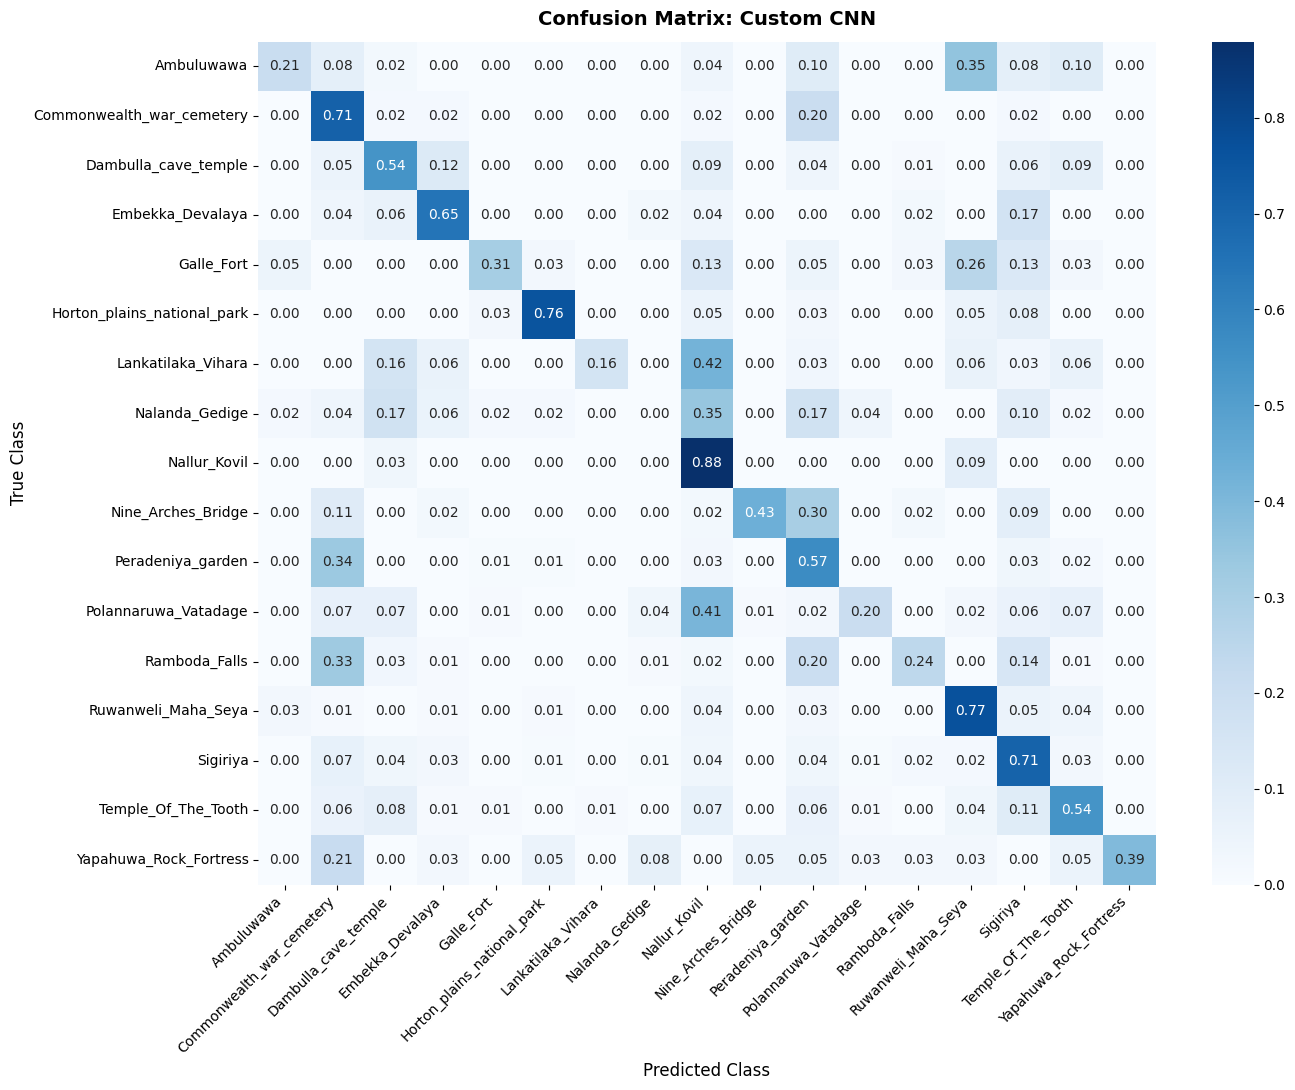

In [20]:
plot_cm(cnn_true, cnn_pred, "Confusion Matrix: Custom CNN", cmap="Blues")

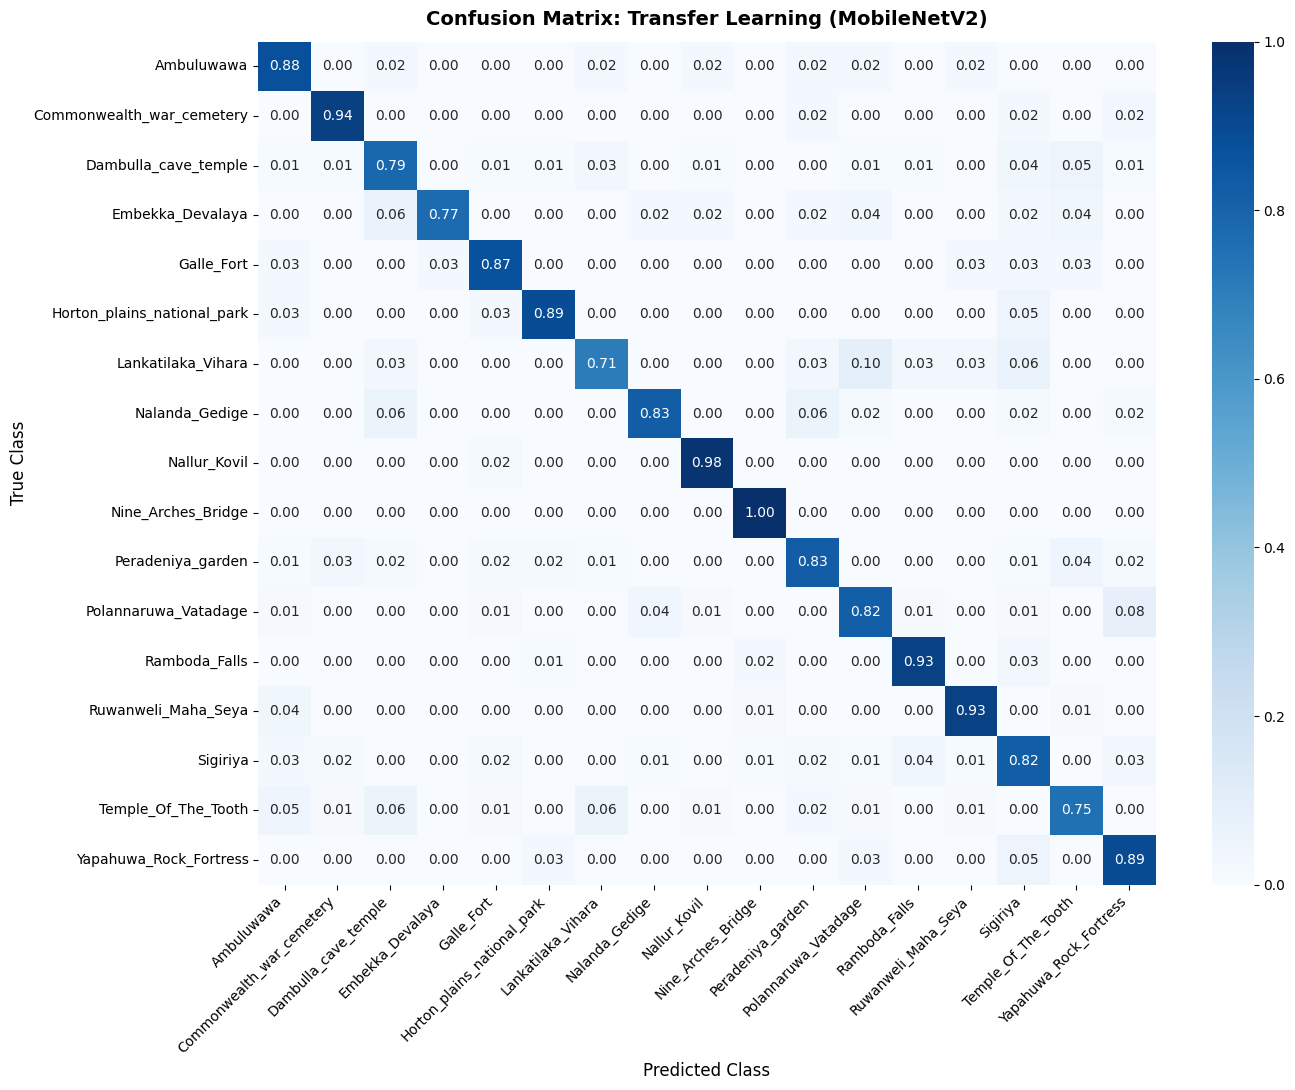

In [21]:
plot_cm(tl_true, tl_pred, "Confusion Matrix: Transfer Learning (MobileNetV2)", cmap="Blues")

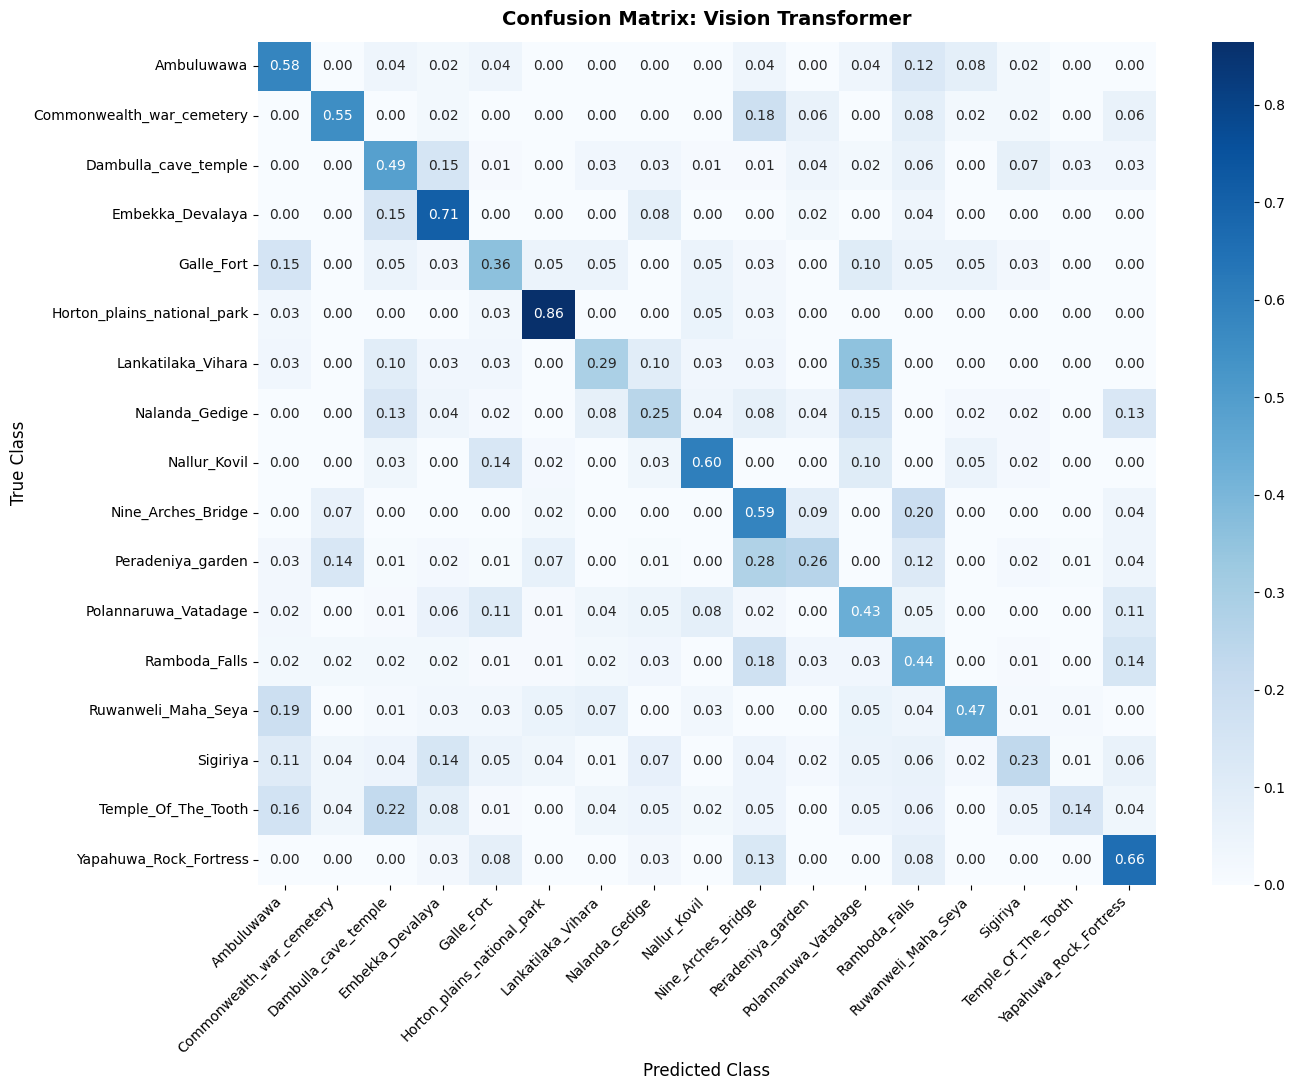

In [22]:
plot_cm(vit_true, vit_pred, "Confusion Matrix: Vision Transformer", cmap="Blues")

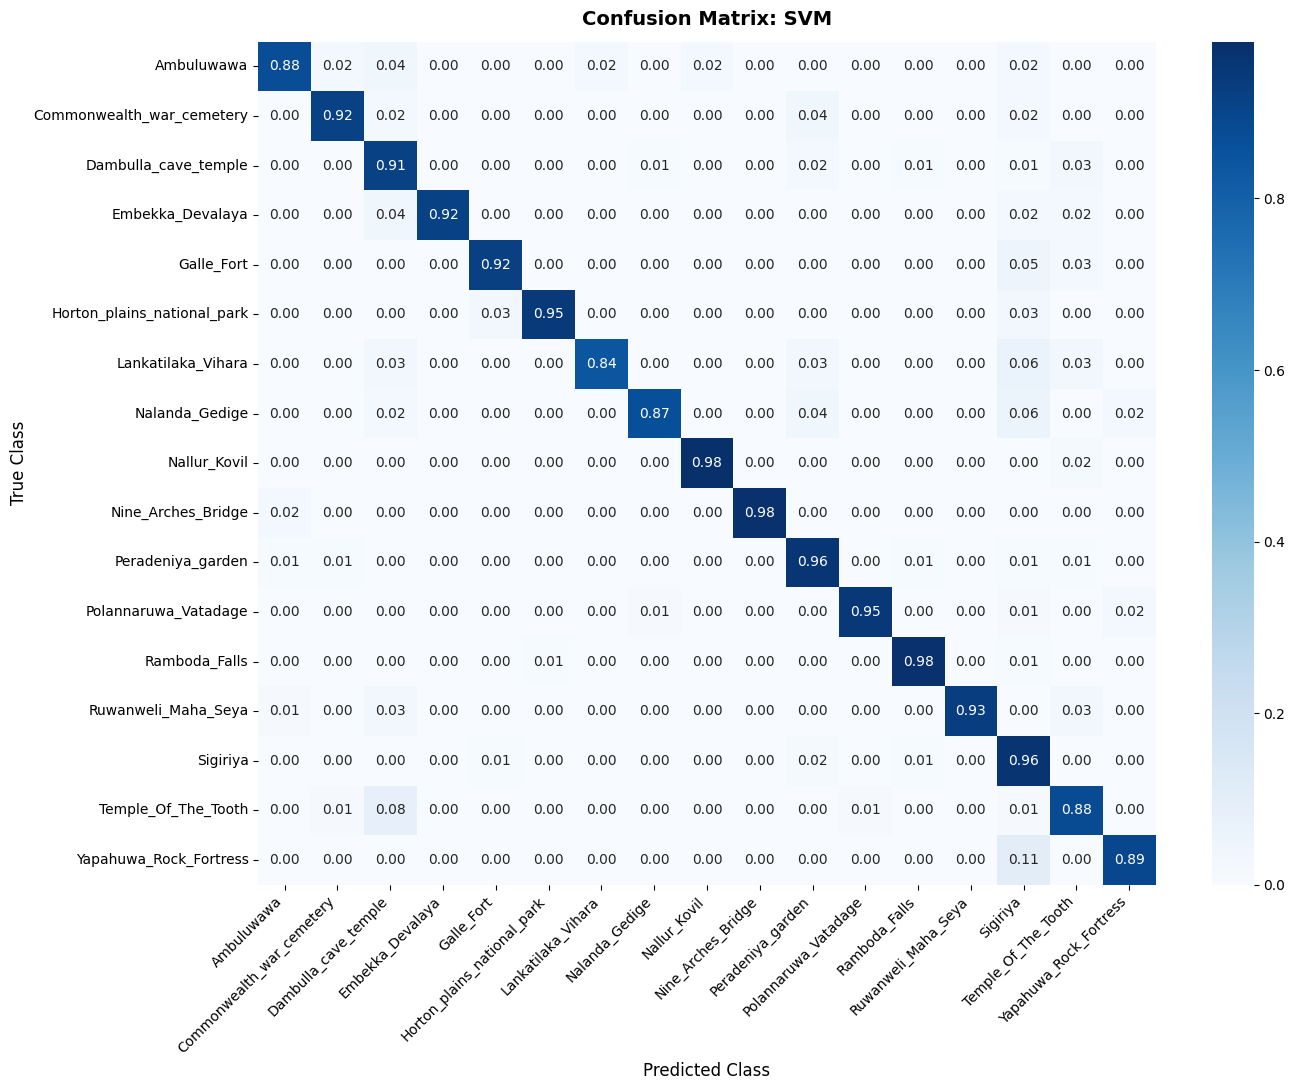

In [23]:
plot_cm(svm_true, svm_pred, "Confusion Matrix: SVM", cmap="Blues")

### Detailed Classification Reports


In [24]:
models_eval = {
    "Custom CNN": (cnn_true, cnn_pred),
    "MobileNetV2 (Fine-Tuned)": (tl_true, tl_pred),
    "Vision Transformer (ViT)": (vit_true, vit_pred),
    "Deep Feature Extractor + SVM": (svm_true, svm_pred)
}

reports = {}
for m_name, (y_t, y_p) in models_eval.items():
    rep = classification_report(y_t, y_p, target_names=class_names, output_dict=True)
    reports[m_name] = rep
    print(f"\n{'='*30} {m_name} {'='*30}")
    print(classification_report(y_t, y_p, target_names=class_names))



============================== Custom CNN ==============================
                             precision    recall  f1-score   support

                 Ambuluwawa       0.67      0.21      0.32        48
  Commonwealth_war_cemetery       0.23      0.71      0.35        49
       Dambulla_cave_temple       0.55      0.54      0.55        94
           Embekka_Devalaya       0.55      0.65      0.60        48
                 Galle_Fort       0.71      0.31      0.43        39
Horton_plains_national_park       0.80      0.76      0.78        37
         Lankatilaka_Vihara       0.83      0.16      0.27        31
             Nalanda_Gedige       0.00      0.00      0.00        52
               Nallur_Kovil       0.33      0.88      0.48        58
         Nine_Arches_Bridge       0.87      0.43      0.58        46
          Peradeniya_garden       0.46      0.57      0.51       116
       Polannaruwa_Vatadage       0.77      0.20      0.32        83
              Ramboda_Falls 

## Training & Validation Accuracy/Loss Curves


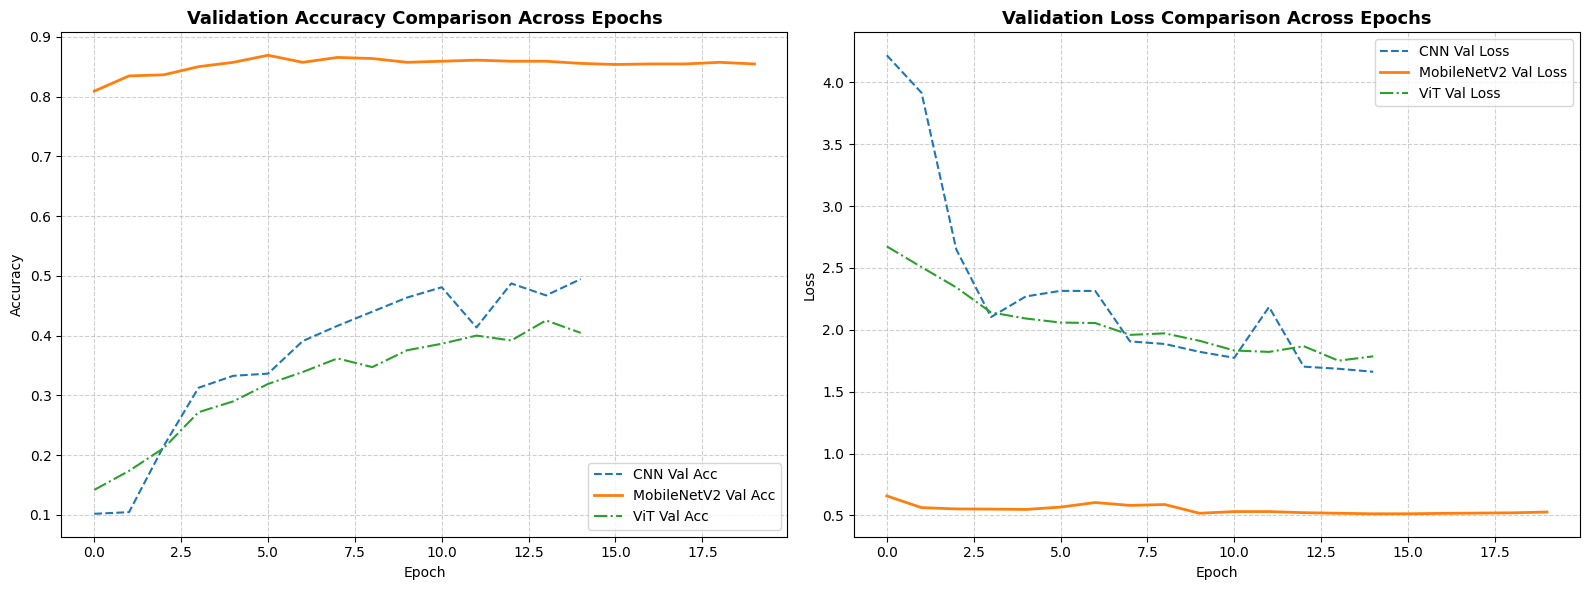

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Accuracy Plot
axes[0].plot(history_cnn.history['val_accuracy'], label='CNN Val Acc', linestyle='--')
axes[0].plot(history_tl_stage1.history['val_accuracy'] + history_tl_stage2.history['val_accuracy'], label='MobileNetV2 Val Acc', linewidth=2)
axes[0].plot(history_vit.history['val_accuracy'], label='ViT Val Acc', linestyle='-.')
axes[0].set_title('Validation Accuracy Comparison Across Epochs', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Loss Plot
axes[1].plot(history_cnn.history['val_loss'], label='CNN Val Loss', linestyle='--')
axes[1].plot(history_tl_stage1.history['val_loss'] + history_tl_stage2.history['val_loss'], label='MobileNetV2 Val Loss', linewidth=2)
axes[1].plot(history_vit.history['val_loss'], label='ViT Val Loss', linestyle='-.')
axes[1].set_title('Validation Loss Comparison Across Epochs', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## Model Comparison Table


In [26]:
# Extract sample batch for latency benchmark
sample_images, _ = next(iter(val_ds))

# Compute Latency
cnn_lat = benchmark_inference_latency(model_cnn, sample_images)
tl_lat = benchmark_inference_latency(transfer_model, sample_images)
vit_lat = benchmark_inference_latency(model_vit, sample_images)

# SVM Latency
def benchmark_svm_latency(fe_model, scaler_obj, svm_obj, sample_batch, runs=50):
    start = time.time()
    for _ in range(runs):
        feats = fe_model.predict(sample_batch[:1], verbose=0)
        scaled = scaler_obj.transform(feats)
        svm_obj.predict(scaled)
    return ((time.time() - start) / runs) * 1000

svm_lat = benchmark_svm_latency(feature_extractor, scaler, svm_model, sample_images)

# Model file sizes
cnn_size = get_file_size_mb(os.path.join(MODELS_DIR, 'custom_cnn_final.keras'))
tl_size = get_file_size_mb(os.path.join(MODELS_DIR, 'transfer_learning_final.keras'))
vit_size = get_file_size_mb(os.path.join(MODELS_DIR, 'vit_model_final.keras'))
svm_size = get_file_size_mb(os.path.join(MODELS_DIR, 'svm_landmark_classifier.joblib'))

# Build Summary Table
benchmark_data = []
for name, (y_t, y_p) in models_eval.items():
    rep = reports[name]
    acc = rep['accuracy']
    prec = rep['weighted avg']['precision']
    rec = rep['weighted avg']['recall']
    f1 = rep['weighted avg']['f1-score']

    if name == "Custom CNN":
        sz, lat, t_time = cnn_size, cnn_lat, f"{cnn_time_cb.total_time:.1f}s"
    elif name == "MobileNetV2 (Fine-Tuned)":
        sz, lat, t_time = tl_size, tl_lat, f"{tl_time_cb.total_time:.1f}s"
    elif name == "Vision Transformer (ViT)":
        sz, lat, t_time = vit_size, vit_lat, f"{vit_time_cb.total_time:.1f}s"
    else:
        sz, lat, t_time = svm_size, svm_lat, f"{svm_train_duration:.1f}s"

    benchmark_data.append({
        'Model Architecture': name,
        'Accuracy': f"{acc*100:.2f}%",
        'Precision (Weighted)': f"{prec*100:.2f}%",
        'Recall (Weighted)': f"{rec*100:.2f}%",
        'F1-Score (Weighted)': f"{f1*100:.2f}%",
        'Model Size (MB)': f"{sz:.2f} MB" if not np.isnan(sz) else "N/A",
        'Inference Latency (ms)': f"{lat:.2f} ms",
        'Training Duration': t_time
    })

df_benchmark = pd.DataFrame(benchmark_data)
display(df_benchmark)


,Model Architecture,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Model Size (MB),Inference Latency (ms),Training Duration
0,Custom CNN,49.45%,57.86%,49.45%,47.57%,3.49 MB,76.13 ms,477.9s
1,MobileNetV2 (Fine-Tuned),85.55%,85.91%,85.55%,85.54%,44.07 MB,100.63 ms,175.6s
2,Vision Transformer (ViT),42.55%,48.47%,42.55%,41.55%,29.17 MB,80.12 ms,135.1s
3,Deep Feature Extractor + SVM,93.18%,93.48%,93.18%,93.23%,32.13 MB,290.91 ms,74.8s


##  Mobile Model Export (TensorFlow Lite)



In [27]:
from tensorflow.keras import mixed_precision

# Save the fine-tuned model before modifying global policy for TFLite conversion
TRANSFER_MODEL_PATH = os.path.join(MODELS_DIR, 'transfer_learning_final.keras')

# Ensure the global policy is float32 for TFLite conversion compatibility
mixed_precision.set_global_policy('float32')

# Build a fresh model with float32 policy and load weights
# Re-instantiate the model structure with float32 policy active
transfer_model_float32, _ = build_transfer_model(input_shape=IMG_SIZE + (3,), num_classes=num_classes)

# Load the trained weights into this new float32 model instance.
transfer_model_float32.load_weights(TRANSFER_MODEL_PATH)

# Recompile the model with a placeholder optimizer. While not strictly for training,
transfer_model_float32.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), # Use a placeholder optimizer
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Standard Float32 TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(transfer_model_float32)
tflite_float32 = converter.convert()

tflite_path = os.path.join(MODELS_DIR, 'landmark_mobilenet_float32.tflite')
with open(tflite_path, 'wb') as f:
    f.write(tflite_float32)
print(f"Saved Float32 TFLite Model: {tflite_path} ({len(tflite_float32)/(1024*1024):.2f} MB)")

# Quantized TFLite (Dynamic Range Quantization for ~4x smaller size and faster mobile CPU inference)
converter_quant = tf.lite.TFLiteConverter.from_keras_model(transfer_model_float32)
converter_quant.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_quant = converter_quant.convert()

tflite_quant_path = os.path.join(MODELS_DIR, 'landmark_mobilenet_quantized.tflite')
with open(tflite_quant_path, 'wb') as f:
    f.write(tflite_quant)
print(f"Saved Quantized TFLite Model: {tflite_quant_path} ({len(tflite_quant)/(1024*1024):.2f} MB)")

mixed_precision.set_global_policy('mixed_float16')

Saved artifact at '/tmp/tmpy7lzmrly'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_244')
Output Type:
  TensorSpec(shape=(None, 17), dtype=tf.float32, name=None)
Captures:
  137943775500560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137940681785808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137940681793872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137940681795216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137940681795792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137940681789648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137940681799632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137940681800016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137940681797520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137940681789840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137940681

## Real Image Prediction & Confidence Visualizer



Testing on sample: /content/DataNew/Ambuluwawa/1 (114).jpg


/tmp/ipykernel_3479/4266583867.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_scores, y=top_names, palette='magma', ax=ax2)


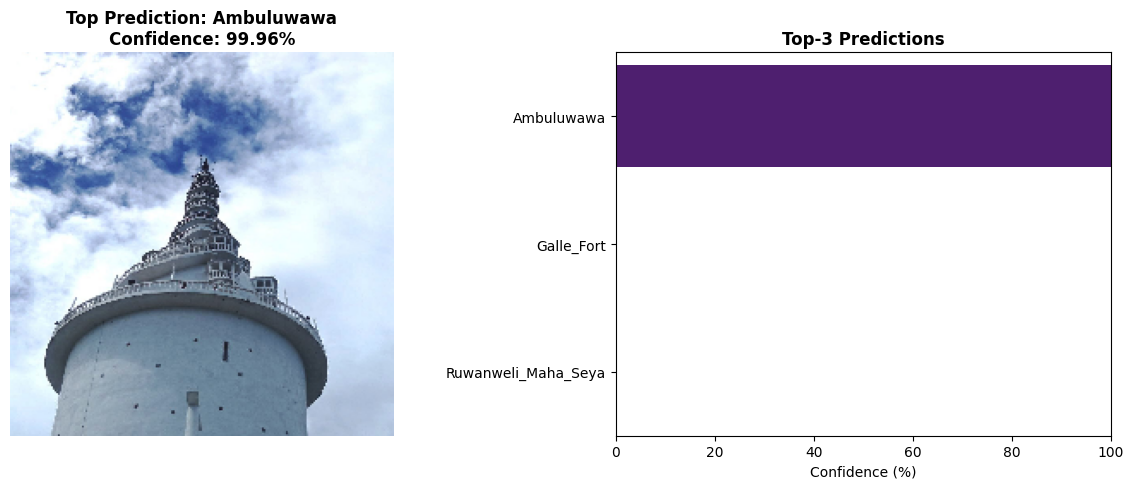

In [28]:
from tensorflow.keras.preprocessing import image

def predict_and_visualize_landmark(img_path, model=transfer_model, top_k=3):
    img = image.load_img(img_path, target_size=IMG_SIZE)
    img_array = image.img_to_array(img)
    img_batch = np.expand_dims(img_array, axis=0)

    # Predict
    preds = model.predict(img_batch, verbose=0)[0]
    top_indices = np.argsort(preds)[::-1][:top_k]

    # Visualize
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    ax1.imshow(img)
    ax1.axis('off')
    ax1.set_title(f"Top Prediction: {class_names[top_indices[0]]}\nConfidence: {preds[top_indices[0]]*100:.2f}%", fontsize=12, fontweight='bold')

    top_names = [class_names[i] for i in top_indices]
    top_scores = [preds[i] * 100 for i in top_indices]

    sns.barplot(x=top_scores, y=top_names, palette='magma', ax=ax2)
    ax2.set_xlim(0, 100)
    ax2.set_xlabel("Confidence (%)")
    ax2.set_title(f"Top-{top_k} Predictions", fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.show()

# Test on a random sample from the dataset
sample_class = class_names[0]
sample_dir = os.path.join(DATASET_PATH, sample_class)
if os.path.exists(sample_dir):
    sample_imgs = [f for f in os.listdir(sample_dir) if f.lower().endswith(valid_exts)]
    if sample_imgs:
        sample_path = os.path.join(sample_dir, sample_imgs[0])
        print(f"Testing on sample: {sample_path}")
        predict_and_visualize_landmark(sample_path)


### Upload Real Image for Prediction

Saving Screenshot 2026-08-31 115001.png to Screenshot 2026-08-31 115001.png
Uploaded file: Screenshot 2026-08-31 115001.png


/tmp/ipykernel_3479/4266583867.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_scores, y=top_names, palette='magma', ax=ax2)


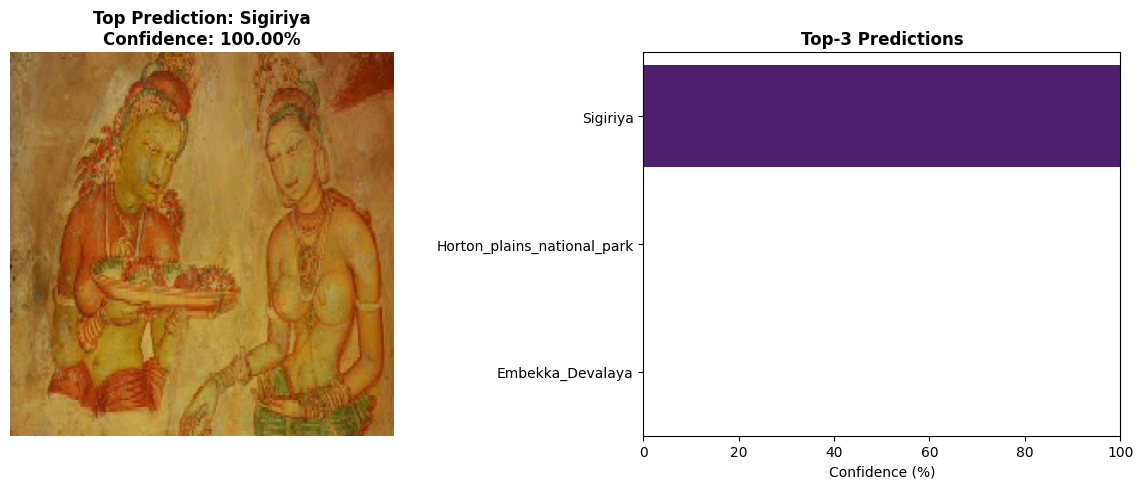

In [29]:
from google.colab import files

# Upload the image
uploaded = files.upload()

for filename in uploaded.keys():
  print(f'Uploaded file: {filename}')
  predict_and_visualize_landmark(filename)

Saving Screenshot 2026-08-31 115554.png to Screenshot 2026-08-31 115554.png
Uploaded file: Screenshot 2026-08-31 115554.png


/tmp/ipykernel_3479/4266583867.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_scores, y=top_names, palette='magma', ax=ax2)


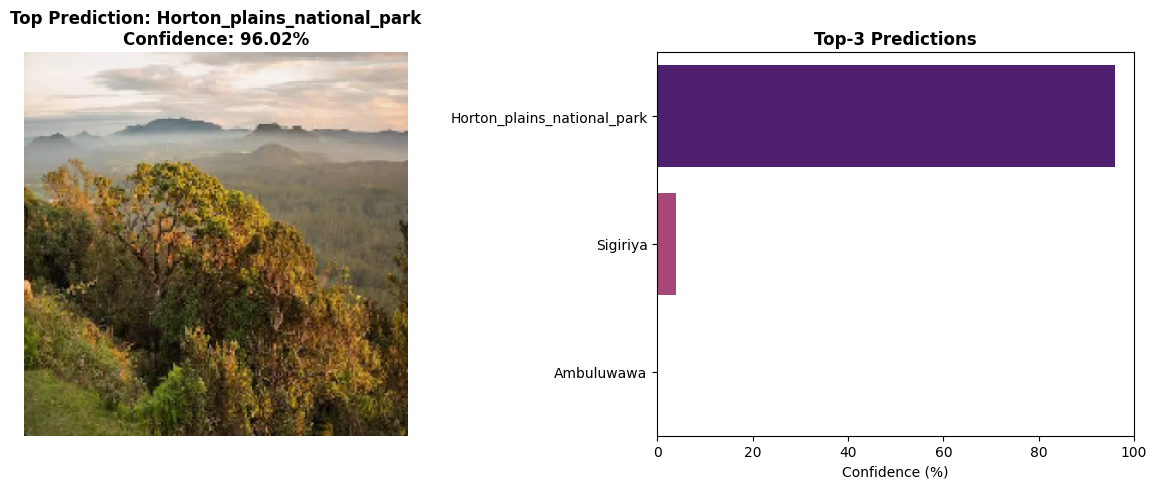

In [30]:
from google.colab import files

# Upload the image
uploaded = files.upload()

for filename in uploaded.keys():
  print(f'Uploaded file: {filename}')
  predict_and_visualize_landmark(filename)

Saving Screenshot 2026-08-31 115009.png to Screenshot 2026-08-31 115009.png
Uploaded file: Screenshot 2026-08-31 115009.png


/tmp/ipykernel_3479/4266583867.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_scores, y=top_names, palette='magma', ax=ax2)


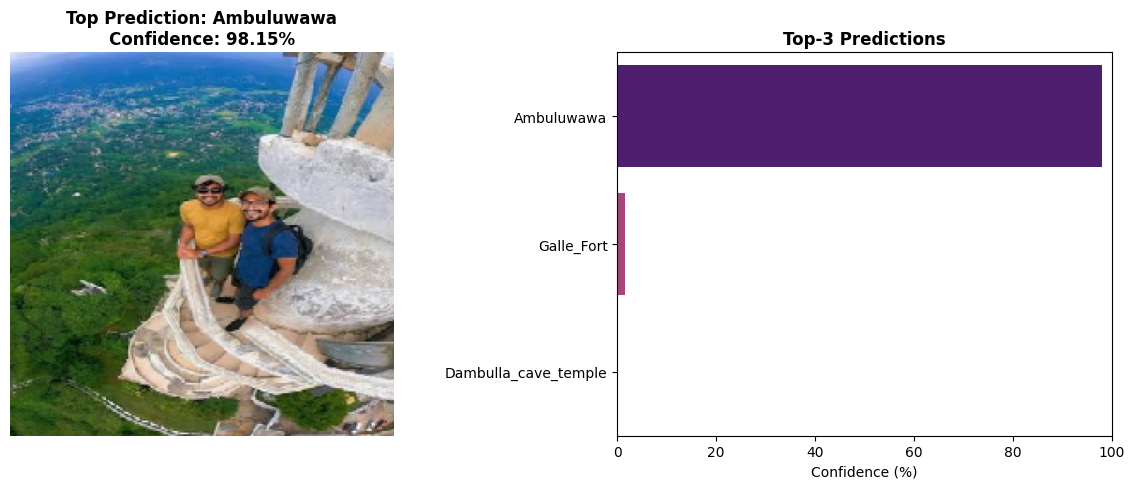

In [31]:
from google.colab import files

# Upload the image
uploaded = files.upload()

for filename in uploaded.keys():
  print(f'Uploaded file: {filename}')
  predict_and_visualize_landmark(filename)

Saving Screenshot 2026-08-31 114945.png to Screenshot 2026-08-31 114945.png
Uploaded file: Screenshot 2026-08-31 114945.png


/tmp/ipykernel_3479/4266583867.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_scores, y=top_names, palette='magma', ax=ax2)


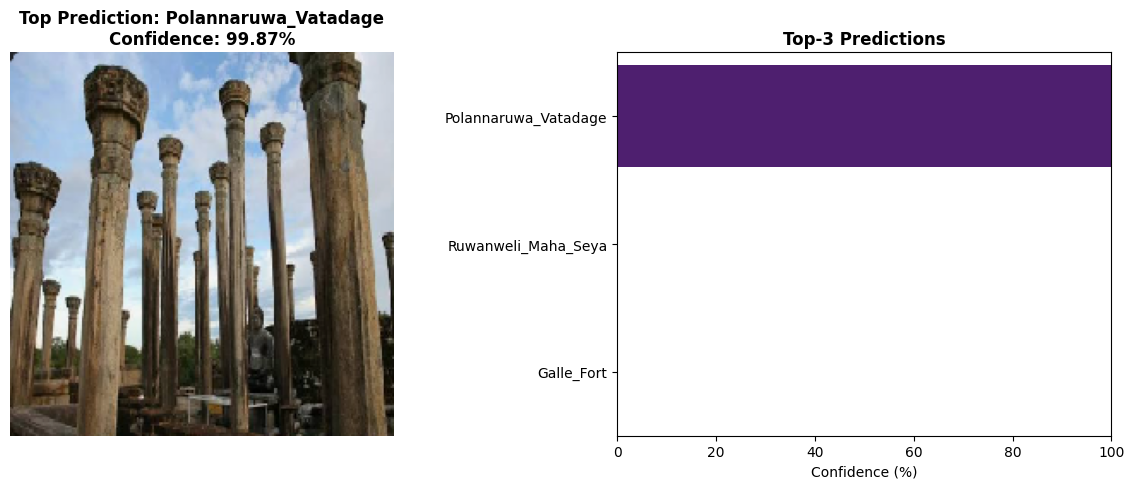

In [32]:
from google.colab import files

# Upload the image
uploaded = files.upload()

for filename in uploaded.keys():
  print(f'Uploaded file: {filename}')
  predict_and_visualize_landmark(filename)